In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df=pd.read_csv('zomato.csv')
df.shape

(51717, 17)

In [4]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='object')

In [5]:
df.info()
df.describe(include='all')

print(df.dtypes)

print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [6]:
df.drop_duplicates(inplace=True)

df.drop(columns=['url', 'phone'], inplace=True, errors='ignore')

# Create a new column for restaurant cost
if 'approx_cost(for two people)' in df.columns:
    df['approx_cost(for two people)'] = pd.to_numeric(
        df['approx_cost(for two people)'].astype(str).str.replace(',', ''),
        errors='coerce'
    )

print("Data transformation completed!")

Data transformation completed!


In [7]:
# Check missing values before imputation
print("Before imputation:")
print(df.isnull().sum())

# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Replace missing values with column means
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# Check missing values after imputation
print("\nAfter imputation:")
print(df.isnull().sum())

Before imputation:
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

After imputation:
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two peop

In [8]:
# Convert restaurant ratings into numerical values

if 'rate' in df.columns:
    df['rate'] = pd.to_numeric(
        df['rate'].astype(str).str.extract(r'(\d+\.?\d*)')[0],
        errors='coerce'
    )

    df['rate'] = df['rate'].fillna(df['rate'].mean())

print("Rating conversion completed!")

Rating conversion completed!


In [9]:
top_restaurants = df.sort_values(
    by='rate', ascending=False
)

print(top_restaurants[['name', 'rate']].head(10))

                                 name  rate
20314  Asia Kitchen By Mainland China   4.9
8260        AB's - Absolute Barbecues   4.9
10284          Belgian Waffle Factory   4.9
8275   Asia Kitchen By Mainland China   4.9
37099       AB's - Absolute Barbecues   4.9
10389       AB's - Absolute Barbecues   4.9
38457          Belgian Waffle Factory   4.9
19393       AB's - Absolute Barbecues   4.9
3921      Byg Brewski Brewing Company   4.9
5153           Belgian Waffle Factory   4.9


In [10]:
average_rating = df['rate'].mean()

print("Average Restaurant Rating:", round(average_rating, 2))

Average Restaurant Rating: 3.7


In [ ]:
popular_locations = df['location'].value_counts().head(10)

print(popular_locations)

location
BTM                      5124
HSR                      2523
Koramangala 5th Block    2504
JP Nagar                 2235
Whitefield               2144
Indiranagar              2083
Jayanagar                1926
Marathahalli             1846
Bannerghatta Road        1630
Bellandur                1286
Name: count, dtype: int64


In [11]:
cost_analysis = df.groupby('location')[
    'approx_cost(for two people)'
].mean().sort_values(ascending=False)

print(cost_analysis.head(10))

location
Sankey Road         2505.555556
Race Course Road    1309.352518
Lavelle Road        1299.399980
MG Road             1140.011283
Infantry Road       1062.251656
Residency Road       965.711750
Langford Town        883.333333
St. Marks Road       871.306818
Cunningham Road      864.969450
Church Street        834.885764
Name: approx_cost(for two people), dtype: float64


In [12]:
online_orders = df['online_order'].value_counts()

print(online_orders)

online_order
Yes    30444
No     21273
Name: count, dtype: int64


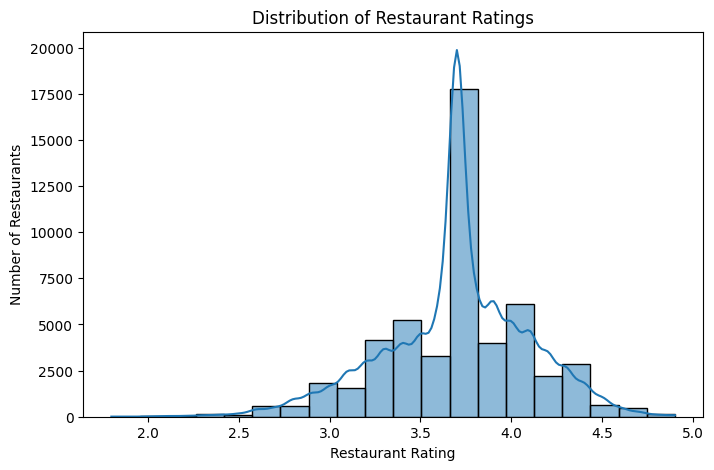

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(df['rate'], bins=20, kde=True)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Restaurants")

plt.show()

In [18]:
popular_locations = df['location'].value_counts().head(10)

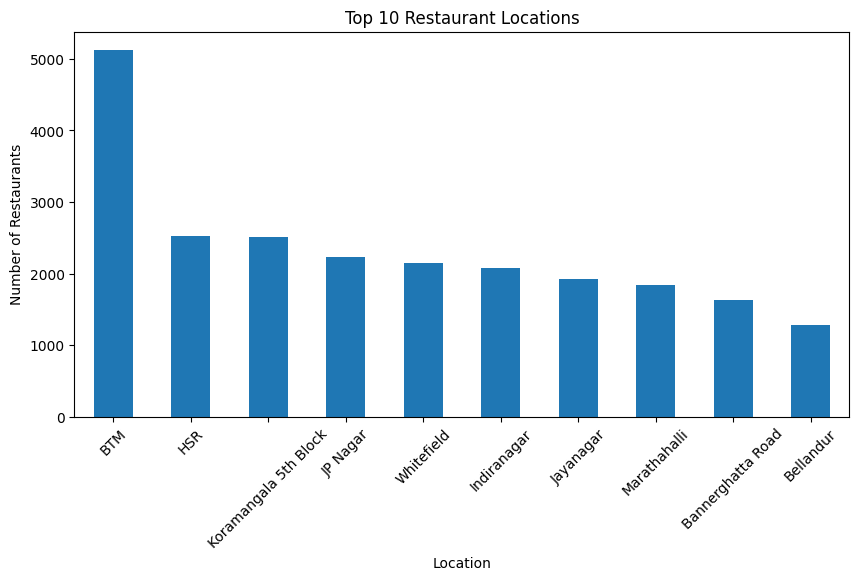

In [19]:
plt.figure(figsize=(10,5))

popular_locations.plot(kind='bar')

plt.title("Top 10 Restaurant Locations")
plt.xlabel("Location")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.show()

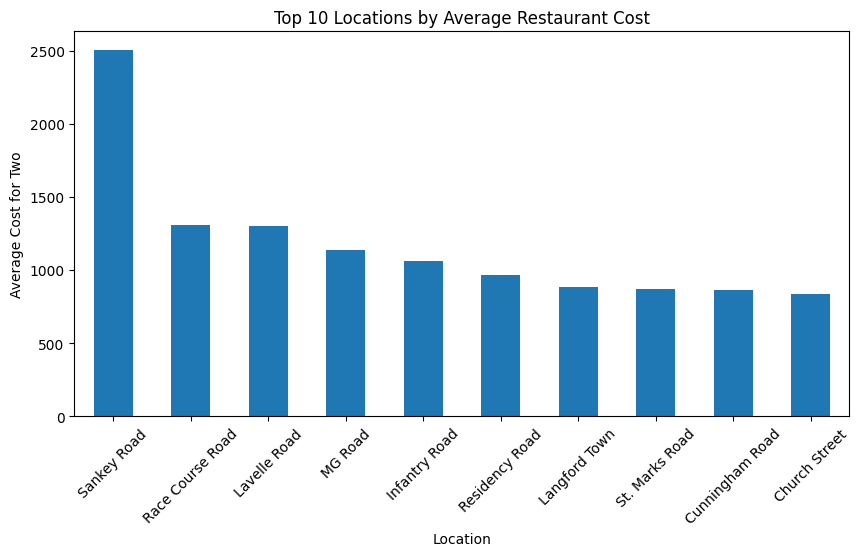

In [16]:
plt.figure(figsize=(10,5))

cost_analysis.head(10).plot(kind='bar')

plt.title("Top 10 Locations by Average Restaurant Cost")
plt.xlabel("Location")
plt.ylabel("Average Cost for Two")

plt.xticks(rotation=45)
plt.show()

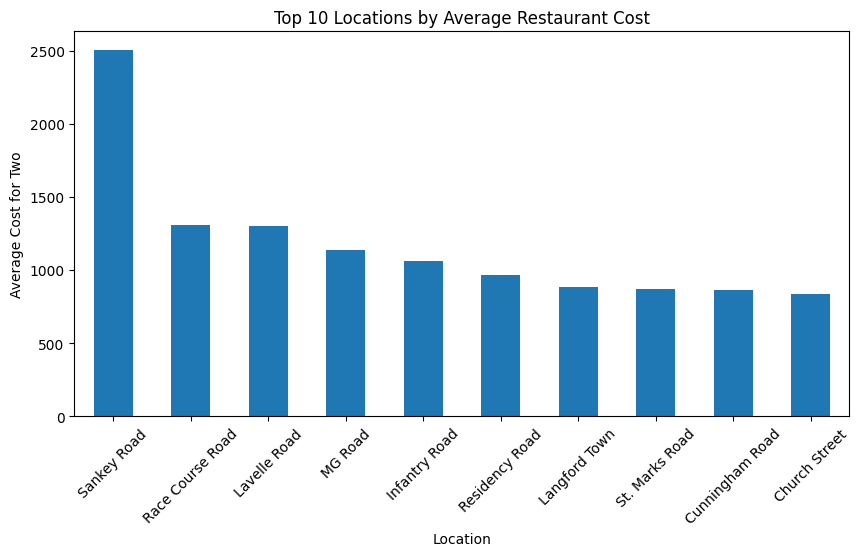

In [ ]:
plt.figure(figsize=(10,5))

cost_analysis.head(10).plot(kind='bar')

plt.title("Top 10 Locations by Average Restaurant Cost")
plt.xlabel("Location")
plt.ylabel("Average Cost for Two")

plt.xticks(rotation=45)
plt.show()

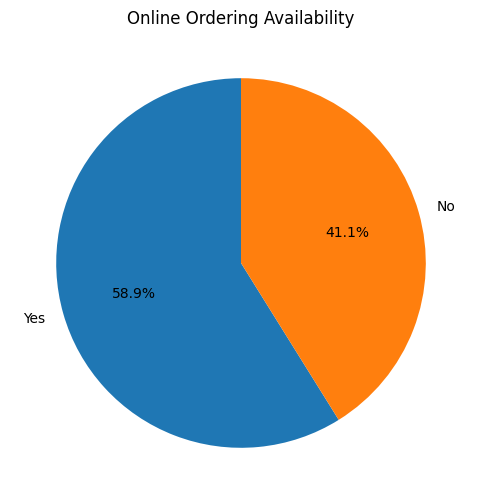

In [20]:
plt.figure(figsize=(6,6))

plt.pie(
    online_orders.values,
    labels=online_orders.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Online Ordering Availability")
plt.show()

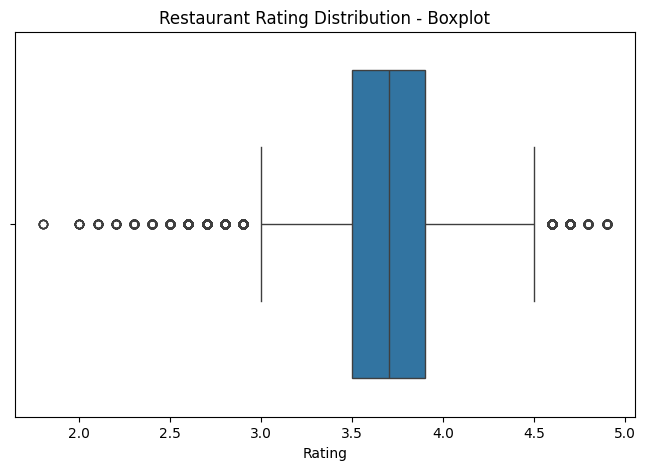

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['rate'])

plt.title("Restaurant Rating Distribution - Boxplot")
plt.xlabel("Rating")

plt.show()

In [ ]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst Five Records:")
display(df.head())

Final Dataset Shape: (51717, 15)

Missing Values:
address                            0
name                               0
online_order                       0
book_table                         0
rate                               0
votes                              0
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)        0
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

First Five Records:


,address,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [22]:
# Select only useful columns
selected_columns = [
    'name',
    'online_order',
    'book_table',
    'rate',
    'votes',
    'location',
    'rest_type',
    'cuisines',
    'approx_cost(for two people)',
    'listed_in(type)',
    'listed_in(city)'
]

# Create reduced dataset
small_df = df[selected_columns].copy()

# Save reduced CSV
small_df.to_csv("zomato_cie.csv", index=False)

print("Reduced dataset created!")
print("Shape:", small_df.shape)

Reduced dataset created!
Shape: (51717, 11)
